# Model 4 - Diffusion, retrained on the FastSpeech mels
Same architecture and recipe as before. The old diffusion checkpoints are renamed (not deleted) so training starts fresh on the new aligned coarse mels.

In [1]:
import sys, torch
ROOT = r"C:\Users\INTEL\Downloads\voice_cloning_v2_1\voice_cloning_v2_1"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - select the Python 3.11.9 kernel")

GPU: NVIDIA GeForce RTX 4070


In [2]:
import os, glob
ck = os.path.join(ROOT, 'checkpoints')
for f in glob.glob(os.path.join(ck, 'diffusion_*.pt')):
    os.replace(f, f.replace('diffusion_', 'baseline_diffusion_'))
    print('kept old file as', os.path.basename(f).replace('diffusion_', 'baseline_diffusion_'))

kept old file as baseline_diffusion_best.pt
kept old file as baseline_diffusion_resume.pt


[diffusion] starting fresh
[diffusion] epoch 1/40  train=0.1467  val=0.0591  (36s)  * best
[diffusion] epoch 2/40  train=0.0500  val=0.0453  (33s)  * best
[diffusion] epoch 3/40  train=0.0472  val=0.0435  (33s)  * best
[diffusion] epoch 4/40  train=0.0459  val=0.0427  (35s)  * best
[diffusion] epoch 5/40  train=0.0447  val=0.0422  (35s)  * best
[diffusion] epoch 6/40  train=0.0444  val=0.0418  (36s)  * best
[diffusion] epoch 7/40  train=0.0446  val=0.0415  (33s)  * best
[diffusion] epoch 8/40  train=0.0437  val=0.0413  (35s)  * best
[diffusion] epoch 9/40  train=0.0440  val=0.0411  (33s)  * best
[diffusion] epoch 10/40  train=0.0436  val=0.0410  (33s)  * best
[diffusion] epoch 11/40  train=0.0435  val=0.0409  (34s)  * best
[diffusion] epoch 12/40  train=0.0434  val=0.0408  (34s)  * best
[diffusion] epoch 13/40  train=0.0431  val=0.0408  (33s)  * best
[diffusion] epoch 14/40  train=0.0429  val=0.0406  (33s)  * best
[diffusion] epoch 15/40  train=0.0432  val=0.0406  (36s)  * best
[diffus

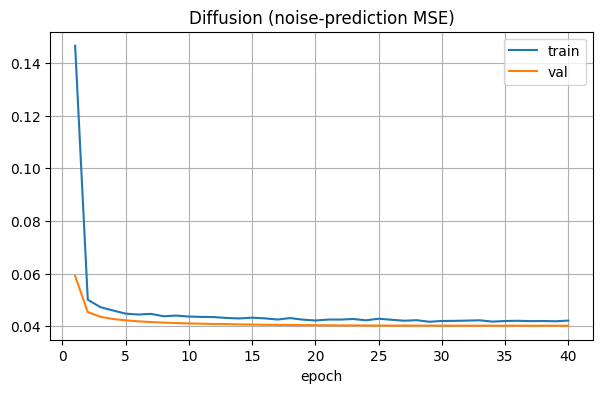

In [3]:
from vc_lib import train_diffusion
from vc_lib.common import plot_history

hist = train_diffusion.train(ROOT, epochs=40, batch_size=32, lr=2e-4)
plot_history(hist, ['train', 'val'], 'Diffusion (noise-prediction MSE)')

## Coarse vs refined vs ground truth

c:\Users\INTEL\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


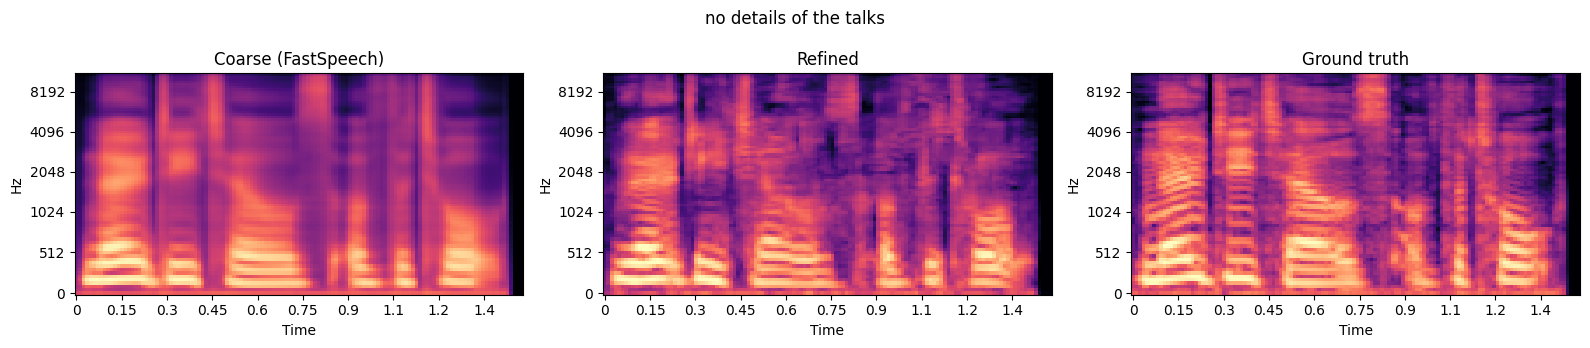

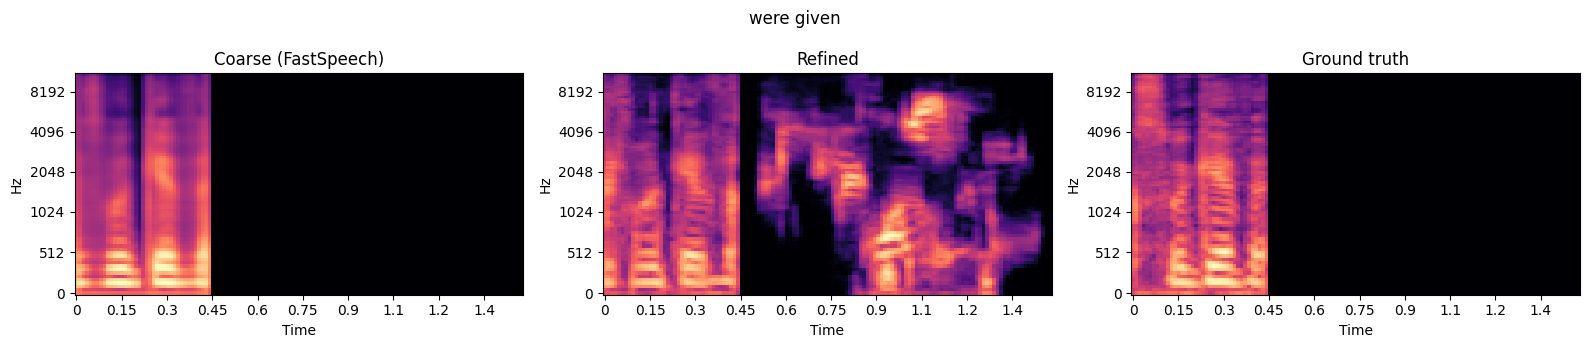

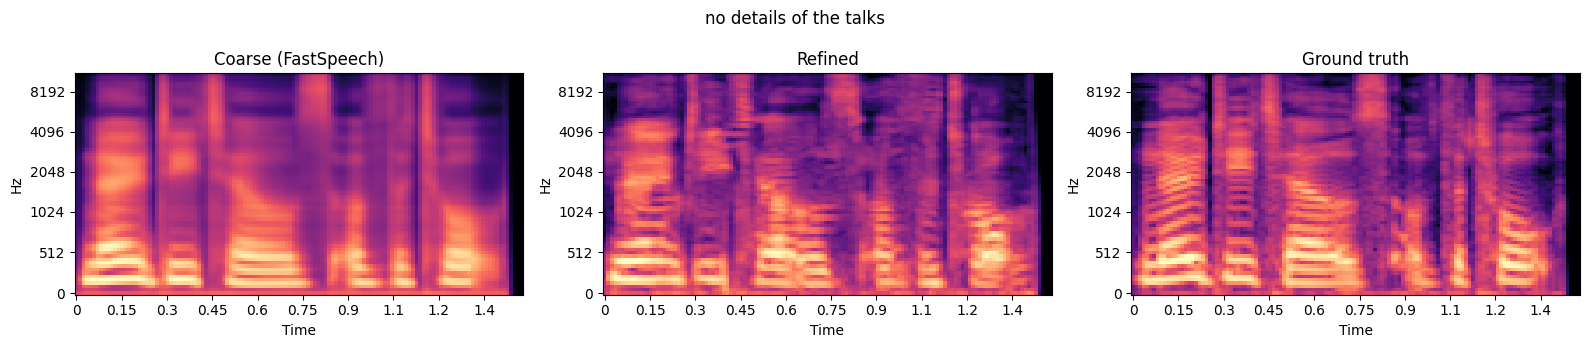

In [4]:
import torch, matplotlib.pyplot as plt, librosa.display
from vc_lib.common import paths, load_cache, tload, device, SR
p = paths(ROOT); C = load_cache(p); CC = tload(p['coarse'])
net = train_diffusion.load_diffusion(ROOT); sch = train_diffusion.Schedule(200)
rows = C['idx']['val'][:3]
coarse = CC['coarse'][rows].float().unsqueeze(1).to(device); spk = CC['spk_emb'][rows].to(device)
ref = train_diffusion.ddim_sample(net, sch, coarse, spk, steps=50, cfg=1.0, seed=0)
for r, i in enumerate(rows.tolist()):
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
    for a, d, t in zip(ax, [coarse[r], ref[r], C['mels'][i]], ['Coarse (FastSpeech)', 'Refined', 'Ground truth']):
        librosa.display.specshow(d.squeeze().float().cpu().numpy(), ax=a, sr=SR, hop_length=256, x_axis='time', y_axis='mel'); a.set_title(t)
    fig.suptitle(C['texts'][i]); plt.tight_layout(); plt.show()